# HD DeepDive: NEBULA DEG along the somatic CAG repeat

For each group of cells (analysed separately), one model per gene:

```
counts ~ RESPONSE + COVARIATES [+ factors] + (1 | DONOR),   offset = total_counts
```

and the coefficient of `RESPONSE` is tested.
* Numeric response, default `somatic_expansion = log2(CAGLENGTH / EXP_germline)`: `log2FC` is the change per **doubling** of the expanded allele relative to the inherited length. Cells: HD cases whose HTT read comes from the expanded allele.
* Categorical response (e.g. `Status`): `log2FC` of `RESPONSE_TESTED` vs `RESPONSE_BASELINE`.

**Groups**: the cell types are the values of `CELLTYPE_COL`. With `MERGE_CELL_TYPES = False` every cell type is analysed on its own; with `True` only the merged groups of `CELLTYPE_MERGE` are analysed (e.g. Matrix_D1 + Matrix_D2 → Matrix) and the other cell types are ignored. Only groups that have factors are kept (e.g. a BICAN PCA file of the same name).

**Factors** (`FACTOR_METHOD`), computed on reference cells (`FACTORS_FROM`: `"bican"` or `"healthy_samples"` = Control cells of this dataset) and transferred to every HD cell, so the HD cases never shape them:
* `"pca"`: PCs (BICAN PCA from `PCA_on_BICAN.ipynb`, or fitted here); the model uses PC_1 … knee of the scree plot.
* `"cnmf"`: GEP usages on cNMF spectra trained outside this notebook (`CNMF_SPECTRA`).
* `"dv_score"`: dorsal–ventral position score from genes with a stable spatial gradient in BICAN health and XDP (as in `NucSeq_DEG_factors.ipynb`).
* `"none"`: baseline only.

`FACTOR_ASSOCIATION` then keeps all factors, only those associated with the response, or drops those.

**Models** per group: `baseline` (no factors) and one factor model.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from adjustText import adjust_text

from utils import reference_pca

# NEBULA runner of generalisable_DEG: fits gene chunks in parallel in R, returns NEBULA's table
sys.path.insert(0, "/home/gdallagl/myworkdir/data/_old/generalisable_DEG")
from functions import nebula as nebula_runner

%matplotlib inline

ADATA_PATH = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_DEEPDIVE_curated.h5ad"
DONOR_COL = "DONOR"
LIBRARY_SIZE_COL = "total_counts"

# ------------------------------------------------------------------------------------------ groups of cells
# column with the cell types
CELLTYPE_COL = "ct_for_deg"
# False: every cell type of CELLTYPE_COL is analysed on its own (cell types starting with "-" are removed)
# True:  only the merged groups of CELLTYPE_MERGE are analysed, all other cell types are ignored
# ATTNETION: a cell tyep cannpot be in mroe then one group, other wise dorn knwohee to put it --> MAKE MULTIPLE RUNS
MERGE_CELL_TYPES = True
CELLTYPE_MERGE = {               # merged group -> cell types pooled into it
    
    # "Matrix": ["Matrix_D1", "Matrix_D2"],
    # "Patch":  ["Patch_D1", "Patch_D2"],

    "MSN": ["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "-phase_D"]
}
# example, all MSNs + phase D as one group:
#   CELLTYPE_MERGE = {"MSN": ["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "-phase_D"]}
#   (then remove "msn_subtype" from COVARIATES: phase D cells have no D1/D2 label, so that level would absorb the long-repeat effect)
# ATTENTION: only groups with factors are analysed: FACTORS_FROM = "bican" needs a BICAN file of the same name
# in BICAN_PCA_DIR (made by PCA_on_BICAN.ipynb), dv_score needs an entry in DV_GRADIENT_CT

# ------------------------------------------------------------------------------------------ tested variable
RESPONSE = "somatic_expansion"   # numeric, HD repeat (only cells whose HTT read comes from the expanded allele, see "Repeat length"):
                                 #   somatic_expansion = log2(CAGLENGTH / EXP_germline), somatic_gain_CAG = CAGLENGTH - EXP_germline, expanded_CAGLENGTH
                                 # categorical: any obs column, e.g. "Status" (Case vs Control; ATTENTION: DeepDive has ONE control donor)
RESPONSE_TYPE = "numeric"        # "numeric" or "categorical"
RESPONSE_BASELINE = None         # categorical only: reference level, e.g. "Control"
RESPONSE_TESTED = None           # categorical only: level tested against the baseline, e.g. "Case"

# ------------------------------------------------------------------------------------------ covariates
# column -> numeric / categorical; covariates constant in a group are dropped
COVARIATES = {"Age": "numeric", "Sex": "categorical", "pct_counts_mt": "numeric", "msn_subtype": "categorical"}

# z-scored over the model cells of each group (only their own coefficients change, not the tested one)
STANDARDISE = ["Age", "pct_counts_mt"]
STANDARDISE_FACTORS = True # eg PCs

# ------------------------------------------------------------------------------------------ cells and genes
MIN_CELLS_PER_DONOR = 10     # donors with fewer model cells in a group are removed from that group
MIN_DONORS = 3               # groups with fewer donors left are skipped
MIN_COUNTS_PER_GENE = 50     # gene tested if >= this many counts AND detected in >= n_donors x MIN_CELLS_PER_DONOR cells

# genes forced to be tested
HANDSAKER_GENES_DIR = "/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all"
FORCE_KEEP_PHASES = ["c_plus", "c_minus", "d"]   # Handsaker phase genes tested anyway, if detected in >= 1 cell

# ------------------------------------------------------------------------------------------ factors
FACTOR_METHOD = "pca"            # "none", "pca", "cnmf", "dv_score"
FACTORS_FROM = "bican"           # pca / cnmf reference: "bican" or "healthy_samples" (Control cells of this dataset)

# factors associated with the response (LMM factor ~ response + covariates + (1|donor))
FACTOR_ASSOCIATION = "all"       # "all": keep every factor | "only_associated": keep only them | "drop_associated": remove them
ASSOC_FDR = 0.05                 # associated = FDR below this ...
ASSOC_MIN_ABS_BETA = 0.1         # ... and |beta| >= this (factor SDs per unit of the response, or tested vs baseline)

# pca psrmted in case i wan tto clalte form helhty of thsi dataset
BICAN_PCA_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/pca_bican"   # from PCA_on_BICAN.ipynb
MIN_CELLS_PER_GENE_REF = 5       # healthy_samples: same PCA steps as the BICAN notebook
TARGET_SUM = 1e4
N_HVG = 3000
N_PCS = 50
SEED = 0
N_PCS_TO_TEST = 20               # PCs tested for association with the response (at least up to the knee)

# cnmf: spectra (*.spectra.k_K.dt_D.consensus.txt, GEPs x genes) trained outside this notebook on the reference counts:
#   bican:           {BICAN_PCA_DIR}/cnmf_input/<group>.h5ad (written by PCA_on_BICAN.ipynb)
#   healthy_samples: {OUT_DIR}/<group>/cnmf_input.h5ad (written here for a group without spectra; the notebook then stops)
CNMF_SPECTRA = {}                # group -> spectra file
CNMF_NORMALISE = True            # usages as fractions per cell; the last GEP is then dropped (the fractions sum to 1)

# dv_score: gradient genes from the BICAN spatial correlations, health and XDP
DV_CORR_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/genes_correlation"
DV_GRADIENT_CT = {"Matrix": "Matrix", "Patch": "Patch"}   # group -> gradient columns used (rho_<ct>: Matrix, Patch, eMSN)
DV_MIN_ABS_RHO = 0.2             # |rho| at least this in EACH condition, same sign
DV_PADJ = 0.05
DV_MIN_PCT_EXPR = 0.20
DV_MIN_MEAN_EXPR = 0.10

# ------------------------------------------------------------------------------------------ NEBULA
NEBULA_METHOD = "LN"
N_FOLDS = 40                 # gene chunks
N_CORES = 40                 # chunks fitted in parallel
NEBULA_CPC = 0               # NEBULA's own gene filter, lowered so that the forced genes are kept (defaults 0.005 and 5)
NEBULA_MINCP = 1
FDR = 0.05

# ------------------------------------------------------------------------------------------ plots
N_LABELS = 10                # volcano: significant genes with the largest |log2FC| labelled

OUT_DIR = f"/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/{RESPONSE}__{FACTOR_METHOD}_{FACTORS_FROM}"
os.makedirs(OUT_DIR, exist_ok=True)

# name of the tested coefficient in NEBULA's output (R names a categorical level <column><level>, e.g. StatusCase)
coef = RESPONSE if RESPONSE_TYPE == "numeric" else RESPONSE + RESPONSE_TESTED
OUT_DIR

'/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/somatic_expansion__pca_bican'

# Load the cells of the groups
Groups: every cell type of `CELLTYPE_COL`, or only the merged groups (`MERGE_CELL_TYPES`). Groups without factors are skipped.

All donors and statuses are loaded: the Control cells are needed for `FACTORS_FROM = "healthy_samples"`.

In [2]:
adata = sc.read_h5ad(ADATA_PATH, backed="r")
celltype = adata.obs[CELLTYPE_COL].astype(str)
print(celltype)

# group of each cell
if MERGE_CELL_TYPES:
    celltype_to_group = {ct: group for group, cts in CELLTYPE_MERGE.items() for ct in cts}
    cell_group = celltype.map(celltype_to_group)                # cell types not merged -> NaN (ignored)
else:
    cell_group = celltype.where(~celltype.isin(["-Low_quality"]))
print(cell_group)

# filter to only groups that have factors rpecalutled in bican, if i want facotrs from bican
groups = sorted(cell_group.dropna().unique())
if FACTOR_METHOD == "pca" and FACTORS_FROM == "bican":
    skipped = [g for g in groups if not os.path.exists(f"{BICAN_PCA_DIR}/{g}.h5ad")]
elif FACTOR_METHOD == "cnmf" and FACTORS_FROM == "bican":
    skipped = [g for g in groups if not os.path.exists(f"{BICAN_PCA_DIR}/cnmf_input/{g}.h5ad")]
elif FACTOR_METHOD == "dv_score":
    skipped = [g for g in groups if g not in DV_GRADIENT_CT]
else:
    skipped = []
groups = [g for g in groups if g not in skipped]
print("groups analysed:", groups)
print("skipped, no factors for them:", skipped)

in_groups = cell_group.isin(groups).values
adata = adata[in_groups].to_memory()

# ATTENTION: raw counts in X; var_names are Ensembl IDs (NEBULA runs on them), gene names in var["gene_name"]
adata.X = sp.csr_matrix(adata.layers["counts"]).astype(np.int32)
del adata.layers["counts"], adata.layers["log1p_norm"]
adata.var["gene_name"] = adata.var["gene_symbol"].astype(str)

adata.obs["group"] = cell_group[in_groups].values
adata.obs[DONOR_COL] = adata.obs[DONOR_COL].astype(str)

display(pd.crosstab(adata.obs[CELLTYPE_COL].astype(str), adata.obs["group"]))
pd.crosstab([adata.obs[DONOR_COL], adata.obs["Status"]], adata.obs["group"])

S02205_Caudate_DeepDive_rxn1_TCCTAATTCCACGGAC          Matrix_D2
S02205_Caudate_DeepDive_rxn1_CCCTCTCTCGATTCCC          Matrix_D1
S02205_Caudate_DeepDive_rxn1_ATATCCTGTATGAGGC          Matrix_D1
S02205_Caudate_DeepDive_rxn1_GAGACCCAGCCATATC           Patch_D1
S02205_Caudate_DeepDive_rxn1_AGAGAATTCCGCGATG          Matrix_D1
                                                      ...       
S12365_Caudate_DeepDive_rxn4_GTGATGTAGTATTAGG    Oligodendrocyte
S12365_Caudate_DeepDive_rxn4_AGGATAAAGAATCCCT    Oligodendrocyte
S12365_Caudate_DeepDive_rxn4_AGCGTATGTCGTGATT    Oligodendrocyte
S12365_Caudate_DeepDive_rxn4_CAATACGCAGAGTGTG    Oligodendrocyte
S12365_Caudate_DeepDive_rxn4_CTAACTTTCGGTCTGG    Oligodendrocyte
Name: ct_for_deg, Length: 329791, dtype: object
S02205_Caudate_DeepDive_rxn1_TCCTAATTCCACGGAC    MSN
S02205_Caudate_DeepDive_rxn1_CCCTCTCTCGATTCCC    MSN
S02205_Caudate_DeepDive_rxn1_ATATCCTGTATGAGGC    MSN
S02205_Caudate_DeepDive_rxn1_GAGACCCAGCCATATC    MSN
S02205_Caudate_DeepDive_r

group,MSN
ct_for_deg,
-phase_D,2824
Matrix_D1,34927
Matrix_D2,22601
Patch_D1,9511
Patch_D2,4682


,group,MSN
DONOR,Status,
S02205,Case,1752
S04002,Case,4976
S04577,Control,19612
S05202,Case,3553
S05368,Case,1462
S06758,Case,13265
S07681,Case,10127
S09619,Case,13428
S12365,Case,6370


#  Prepare variables

### HD: flag cells that have repeats from EXP allele
Repeat length (HD only)
`CAGLENGTH` is the length of the **one** HTT molecule read in a cell (NaN = none). A case has a WT and an expanded allele (`CAG = "WT/EXP"`), and the read can come from either: it is counted as expanded if it is longer than the midpoint of the two inherited alleles.

The repeat responses (`somatic_expansion`, `somatic_gain_CAG`, `expanded_CAGLENGTH`) are filled only for reads from the expanded allele: the other cells have NaN and do not enter the model.

In [3]:
obs = adata.obs
obs["Status"] = obs["Status"].astype(str)
obs["Sex"] = obs["Sex"].astype(str)
obs["Age"] = obs["Age"].astype(str).astype(int)
obs["msn_subtype"] = obs[CELLTYPE_COL].astype(str).str.extract(r"_(D1|D2)$")[0].fillna("none").values

# donor genotype "WT/EXP" -> shorter and longer inherited allele
alleles = obs["CAG"].astype(str).str.split("/", expand=True).astype(int)
obs["WT_germline"] = alleles.min(axis=1)
obs["EXP_germline"] = alleles.max(axis=1)
obs["CAGLENGTH"] = obs["CAGLENGTH"].astype(float)

# read from the expanded allele (cases only)
midpoint = (obs["WT_germline"] + obs["EXP_germline"]) / 2
obs["read_from_expanded"] = (obs["Status"] == "Case") & (obs["CAGLENGTH"] > midpoint)

# repeat responses, only for reads from the expanded allele (NaN otherwise)
expanded = obs["read_from_expanded"]
obs["somatic_expansion"] = np.log2(obs["CAGLENGTH"] / obs["EXP_germline"]).where(expanded)   # 0 = inherited length, 1 = doubled
obs["somatic_gain_CAG"] = (obs["CAGLENGTH"] - obs["EXP_germline"]).where(expanded)
obs["expanded_CAGLENGTH"] = obs["CAGLENGTH"].where(expanded)

pd.crosstab([obs[DONOR_COL], obs["Status"], obs["CAG"].astype(str)], obs["read_from_expanded"])

,,read_from_expanded,False,True
DONOR,Status,CAG,,
S02205,Case,20/42,1304,448
S04002,Case,17/42,4849,127
S04577,Control,17/17,19612,0
S05202,Case,15/42,2823,730
S05368,Case,16/39,1351,111
S06758,Case,18/43,10957,2308
S07681,Case,16/42,9397,730
S09619,Case,22/37,13047,381
S12365,Case,17/40,4928,1442


# Cells of the model
Cells of the groups with the response and the covariates not missing; then, per group, donors with ≥ `MIN_CELLS_PER_DONOR` cells. Groups with fewer than `MIN_DONORS` donors left are skipped. A categorical response keeps only `RESPONSE_BASELINE` and `RESPONSE_TESTED` cells, with the baseline as the reference level.

In [4]:
# start to flag only the cell sthat shoduls tai in the modle
# the have a lebeò
# the rpeisne vaurbael is there
in_model = obs["group"].notna() & obs[RESPONSE].notna()
# if id is categorical, only keep baseline and tested levels
if RESPONSE_TYPE == "categorical":
    in_model &= obs[RESPONSE].isin([RESPONSE_BASELINE, RESPONSE_TESTED])
for col in COVARIATES:
    in_model &= obs[col].notna()

# donors with too few cells in a group are removed from that group
cells_per_donor = obs[in_model].groupby(["group", DONOR_COL]).size()
too_few = cells_per_donor[cells_per_donor < MIN_CELLS_PER_DONOR].index
in_model &= ~pd.MultiIndex.from_arrays([obs["group"], obs[DONOR_COL]]).isin(too_few)
obs["in_model"] = in_model
print("removed (group, donor):", list(too_few))

# # groups with too few donors left are skipped
# n_donors = obs[obs["in_model"]].groupby("group")[DONOR_COL].nunique()
# too_few_donors = [g for g in groups if n_donors.get(g, 0) < MIN_DONORS]
# groups = [g for g in groups if g not in too_few_donors]
# print(f"skipped, fewer than {MIN_DONORS} donors:", too_few_donors)

# response type: categorical levels in the order [baseline, tested] (the first is the reference)
if RESPONSE_TYPE == "categorical":
    obs[RESPONSE] = pd.Categorical(obs[RESPONSE].astype(str), categories=[RESPONSE_BASELINE, RESPONSE_TESTED])
else:
    obs[RESPONSE] = obs[RESPONSE].astype(float)

# covariates of each group: constant ones are dropped (e.g. msn_subtype in a D1-only group)
covariates = {}
for group in groups:
    cells = obs[obs["in_model"] & (obs["group"] == group)]
    covariates[group] = [c for c in COVARIATES if cells[c].nunique() > 1]
    print(f"{group}: {len(cells)} cells, {cells[DONOR_COL].nunique()} donors, covariates {covariates[group]}")

cells_per_donor.unstack("group")

removed (group, donor): []
MSN: 6277 cells, 8 donors, covariates ['Age', 'Sex', 'pct_counts_mt', 'msn_subtype']


group,MSN
DONOR,
S02205,448
S04002,127
S05202,730
S05368,111
S06758,2308
S07681,730
S09619,381
S12365,1442


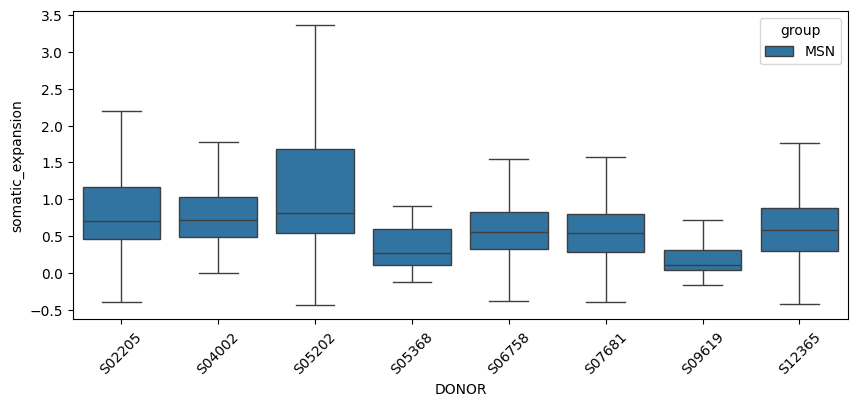

In [5]:
model_obs = obs[obs["in_model"]]
if RESPONSE_TYPE == "numeric":
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=model_obs, x=DONOR_COL, y=RESPONSE, hue="group", showfliers=False)
    plt.xticks(rotation=45)
    plt.savefig(f"{OUT_DIR}/response_by_donor.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    display(pd.crosstab([model_obs["group"], model_obs[DONOR_COL]], model_obs[RESPONSE]))

# Factors
Each group has its own factors (PC_1 of Matrix and PC_1 of Patch are different axes). `factor_names[group]` = the factors of the group; their scores go into `adata.obs`. Only the cell of the chosen `FACTOR_METHOD` does something.

### PCA
One PCA per group, from BICAN (loaded) or from the Control cells of this dataset (fitted here). Every cell of the group is projected onto it with `reference_pca.project_pca`: same normalisation, same HVGs, z-scored with the reference mean / SD, × loadings.

In [6]:
factor_names, scores = {}, []

if FACTOR_METHOD == "pca":
    pcas = {}
    for group in groups:

        # load adata used to calculate pca --> they store PCs, meand, std, HVG, ... all waht is needed to project
        if FACTORS_FROM == "bican":
            pcas[group] = sc.read_h5ad(f"{BICAN_PCA_DIR}/{group}.h5ad")
        elif FACTORS_FROM == "healthy_samples":
            # ATTENTION: DeepDive has ONE control donor -> these PCs also carry that donor's own traits
            healthy = adata[((adata.obs["group"] == group) & (adata.obs["Status"] == "Control")).values].copy()
            sc.pp.filter_genes(healthy, min_cells=MIN_CELLS_PER_GENE_REF)
            pcas[group] = reference_pca.fit_pca(healthy, n_hvg=N_HVG, n_pcs=N_PCS, target_sum=TARGET_SUM, seed=SEED)
        print(f"{group}: PCA from {pcas[group].n_obs} {FACTORS_FROM} cells, {pcas[group].var['highly_variable'].sum()} HVGs")

        print(pcas[group])

        # genes: the BICAN PCA uses gene names, with Ensembl IDs in var["gene_id"]; HD var_names are Ensembl IDs
        match_on = "gene_id" if FACTORS_FROM == "bican" else None
        s = reference_pca.project_pca(adata[(adata.obs["group"] == group).values], pcas[group], match_on=match_on)
        factor_names[group] = list(s.columns)
        scores.append(s)

        #break

MSN: PCA from 112920 bican cells, 3000 HVGs
AnnData object with n_obs × n_vars = 112920 × 35957
    obs: 'donor_id', 'x', 'y', 'zone', 'bican_file', 'r', 'd', 'region'
    var: 'highly_variable', 'mean', 'std', 'gene_id'
    uns: 'target_sum', 'variance_ratio'
    obsm: 'X_pca'
    varm: 'PCs'
  31114/35957 PCA genes found, 2640/3000 HVGs


KeyboardInterrupt: 

### cNMF
Spectra are trained outside this notebook (e.g. on UGER) on the reference counts. A group without a spectra file in `CNMF_SPECTRA` gets its reference counts written (healthy_samples), and the notebook stops. With spectra, each cell's usage is the non-negative least-squares fit of its counts (each gene divided by its SD in the reference counts) on the spectra, as in `nebula_with_factors`.

In [ ]:
# if FACTOR_METHOD == "cnmf":
#     for group in groups:
#         # reference counts, with Ensembl IDs as var_names (as HD)
#         if FACTORS_FROM == "bican":
#             ref = sc.read_h5ad(f"{BICAN_PCA_DIR}/cnmf_input/{group}.h5ad")          # BICAN gene names, IDs in var["gene_id"]
#             name_to_id = dict(zip(ref.var_names, ref.var["gene_id"]))
#             ref = ref[:, (ref.var["gene_id"] != "").values & ~ref.var["gene_id"].duplicated(keep=False).values].copy()
#             ref.var_names = ref.var["gene_id"].values
#         elif FACTORS_FROM == "healthy_samples":
#             ref = adata[((adata.obs["group"] == group) & (adata.obs["Status"] == "Control")).values].copy()
#             name_to_id = None

#         if group not in CNMF_SPECTRA:
#             if FACTORS_FROM == "healthy_samples":
#                 path = f"{OUT_DIR}/{group}/cnmf_input.h5ad"
#                 os.makedirs(os.path.dirname(path), exist_ok=True)
#                 ad.AnnData(ref.X.astype(np.float64), obs=ref.obs[[DONOR_COL]], var=ref.var[["gene_name"]]).write_h5ad(path)   # cNMF needs float64 counts
#             else:
#                 path = f"{BICAN_PCA_DIR}/cnmf_input/{group}.h5ad"
#             raise RuntimeError(f"no cNMF spectra for {group}: train cNMF on {path}, then add CNMF_SPECTRA['{group}']")

#         spectra = pd.read_csv(CNMF_SPECTRA[group], sep="\t", index_col=0)         # GEPs x genes
#         spectra.index = [f"GEP_{i + 1}" for i in range(len(spectra))]
#         if name_to_id is not None:
#             spectra.columns = [name_to_id.get(g, "") for g in spectra.columns]
#             spectra = spectra.loc[:, spectra.columns != ""]

#         print(f"{group}: cNMF {len(spectra)} GEPs, reference {ref.n_obs} {FACTORS_FROM} cells")
#         s = reference_pca.cnmf_usage(adata[(adata.obs["group"] == group).values], spectra, ref, normalise=CNMF_NORMALISE)
#         if CNMF_NORMALISE:
#             s = s.iloc[:, :-1]                    # fractions sum to 1: the last GEP is redundant
#         factor_names[group] = list(s.columns)
#         scores.append(s)

### DV score
Genes whose dorsal–ventral spatial gradient in BICAN is strong **and** agrees in sign in health and XDP (disease-invariant spatial markers), weight = mean ρ of the two. Each cell's score = z-scored log-normalised expression of these genes (within the group) × weights. The columns used for each group are `DV_GRADIENT_CT[group]`.

In [ ]:
# if FACTOR_METHOD == "dv_score":
#     df_corr_health = pd.read_csv(f"{DV_CORR_DIR}/df_corr.csv", index_col=0)
#     df_corr_xdp = pd.read_csv(f"{DV_CORR_DIR}/df_corr_xdp.csv", index_col=0)
#     common_genes = df_corr_health.index.intersection(df_corr_xdp.index)
#     dfh, dfx = df_corr_health.loc[common_genes], df_corr_xdp.loc[common_genes]

#     # gene names -> HD Ensembl IDs (names used by several IDs are left out)
#     names = adata.var["gene_name"]
#     name_to_id = dict(zip(names[~names.duplicated(keep=False)], names[~names.duplicated(keep=False)].index))

#     for group in groups:
#         ct = DV_GRADIENT_CT[group]
#         reliable = pd.Series(True, index=common_genes)
#         for d in [dfh, dfx]:
#             reliable &= (d[f"rho_{ct}"].abs() >= DV_MIN_ABS_RHO) & (d[f"padj_{ct}"] < DV_PADJ)
#             reliable &= (d[f"pct_expr_{ct}"] >= DV_MIN_PCT_EXPR) & (d[f"mean_expr_{ct}"] >= DV_MIN_MEAN_EXPR)
#         stable = reliable & (np.sign(dfh[f"rho_{ct}"]) == np.sign(dfx[f"rho_{ct}"]))
#         weights = (dfh.loc[stable, f"rho_{ct}"] + dfx.loc[stable, f"rho_{ct}"]) / 2
#         weights.index = [name_to_id.get(g, "") for g in weights.index]
#         weights = weights[weights.index != ""]

#         print(f"{group}: {stable.sum()} stable gradient genes ({ct})")
#         s = reference_pca.gradient_score(adata[(adata.obs["group"] == group).values], weights, target_sum=TARGET_SUM)
#         factor_names[group] = ["dv_score"]
#         scores.append(s.to_frame("dv_score"))

In [ ]:
if FACTOR_METHOD != "none":
    scores = pd.concat(scores)
    adata.obs = adata.obs.drop(columns=scores.columns, errors="ignore").join(scores)
    display(adata.obs[["group", *scores.columns[:5]]].head())

,group,PC_1,PC_2,PC_3,PC_4,PC_5
S02205_Caudate_DeepDive_rxn1_TCCTAATTCCACGGAC,MSN,1.400747,6.870311,-2.111760,7.679194,0.292479
S02205_Caudate_DeepDive_rxn1_CCCTCTCTCGATTCCC,MSN,7.505512,4.489523,-1.015053,0.756922,6.870805
S02205_Caudate_DeepDive_rxn1_ATATCCTGTATGAGGC,MSN,-0.703195,3.653105,-5.134817,-0.136229,6.570978
S02205_Caudate_DeepDive_rxn1_GAGACCCAGCCATATC,MSN,-0.564296,3.993447,-14.484640,-8.696731,-5.991419
S02205_Caudate_DeepDive_rxn1_AGAGAATTCCGCGATG,MSN,8.983036,5.879716,-1.463455,-2.893828,1.647819


### Scree plot and knee (PCA only)

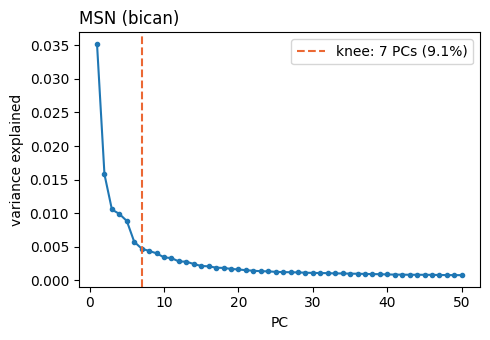

MSN: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7']


In [ ]:
n_knee = {}
if FACTOR_METHOD == "pca":
    fig, axes = plt.subplots(1, len(pcas), figsize=(5 * len(pcas), 3.5), squeeze=False)
    for ax, (group, pca) in zip(axes[0], pcas.items()):
        evr = pca.uns["variance_ratio"]
        n_knee[group] = reference_pca.knee_point(evr)
        ax.plot(np.arange(1, len(evr) + 1), evr, "o-", ms=3)
        ax.axvline(n_knee[group], color="#eb6834", ls="--", label=f"knee: {n_knee[group]} PCs ({evr[:n_knee[group]].sum():.1%})")
        ax.set_xlabel("PC")
        ax.set_ylabel("variance explained")
        ax.set_title(f"{group} ({FACTORS_FROM})", loc="left")
        ax.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/scree.png", dpi=150)
    plt.show()

# factors that can enter the model: PC_1 ... knee, or all GEPs / the DV score
candidates = {}
for group in groups:
    if FACTOR_METHOD == "pca":
        candidates[group] = factor_names[group][:n_knee[group]]
    else:
        candidates[group] = factor_names.get(group, [])
    print(f"{group}: candidate factors {candidates[group]}")

### Are the factors associated with the response?
For each factor, on the model cells of the group: `scale(factor) ~ RESPONSE + covariates + (1 | DONOR)`. `beta` = factor SDs per unit of the response (or tested vs baseline). "Associated" = FDR < `ASSOC_FDR` **and** |beta| ≥ `ASSOC_MIN_ABS_BETA` (with thousands of cells nearly every factor is significant).

An associated factor is either a **confounder** (adjusting is right) or is **moved by the response** (adjusting removes real signal): the data cannot tell the two apart. `FACTOR_ASSOCIATION` decides what to do with them; compare the factor model with the baseline.

`candidate` = the factor can enter the model (PCA: up to the knee). `var_ratio` (PCA) = variance of the PC in the model cells / in the reference: much less than 1 means the axis barely varies here.

MSN: candidate factors associated with somatic_expansion: ['PC_1', 'PC_4', 'PC_5', 'PC_6', 'PC_7']


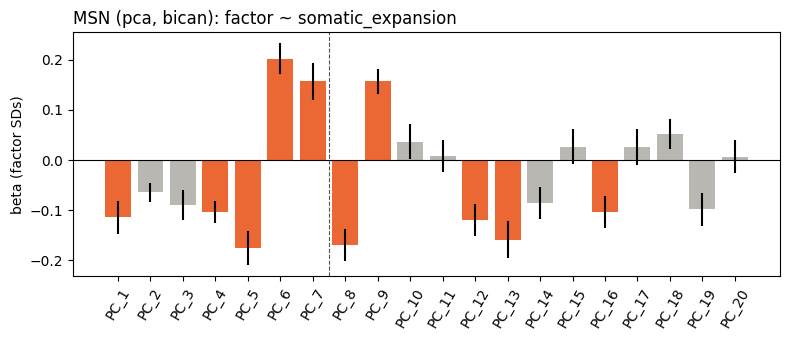

MSN                                                    
         beta     se      p candidate var_ratio    fdr associated
factor                                                           
PC_1   -0.114  0.017  0.000      True     0.173  0.000       True
PC_2   -0.064  0.010  0.000      True     0.689  0.000      False
PC_3   -0.089  0.015  0.000      True     0.464  0.000      False
PC_4   -0.104  0.011  0.000      True     0.709  0.000       True
PC_5   -0.176  0.017  0.000      True     0.617  0.000       True
PC_6    0.202  0.016  0.000      True     0.491  0.000       True
PC_7    0.157  0.019  0.000      True     0.319  0.000       True
PC_8   -0.169  0.016  0.000     False     0.518  0.000       True
PC_9    0.157  0.012  0.000     False     0.650  0.000       True
PC_10   0.037  0.017  0.036     False     0.477  0.045      False
PC_11   0.008  0.016  0.609     False     0.539  0.641      False
PC_12  -0.120  0.016  0.000     False     0.329  0.000       True
PC_13  -0.159  0.019  0.000     False     0.661  0.000       True
PC_14  -0.086  0.016  0.000     False     0.571  0.000      False
PC_15   0.027  0.018  0.137     False     0.466  0.161      False
PC_16  -0.103  0.016  0.000     False     0.556  0.000       True
PC_17   0.026  0.018  0.157     False     0.464  0.174      False
PC_18   0.052  0.015  0.001     False     0.853  0.001      False
PC_19  -0.098  0.017  0.000     False     0.735  0.000      False
PC_20   0.007  0.017  0.673     False     0.621  0.673      False

In [ ]:
# name of the tested term in statsmodels
response_param = RESPONSE if RESPONSE_TYPE == "numeric" else f"{RESPONSE}[T.{RESPONSE_TESTED}]"

assoc = {}
if FACTOR_METHOD != "none":
    for group in groups:
        cells = adata.obs[adata.obs["in_model"] & (adata.obs["group"] == group)].copy()
        to_test = factor_names[group]
        if FACTOR_METHOD == "pca":
            to_test = to_test[:max(N_PCS_TO_TEST, n_knee[group])]

        rows = []
        for i, f in enumerate(to_test):
            cells["y"] = (cells[f] - cells[f].mean()) / cells[f].std()
            formula = "y ~ " + " + ".join([RESPONSE, *covariates[group]])
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = smf.mixedlm(formula, cells, groups=cells[DONOR_COL]).fit()
            row = {"factor": f, "beta": fit.params[response_param], "se": fit.bse[response_param],
                   "p": fit.pvalues[response_param], "candidate": f in candidates[group]}
            if FACTOR_METHOD == "pca":
                row["var_ratio"] = cells[f].var() / pcas[group].obsm["X_pca"][:, i].var()
            rows.append(row)

        a = pd.DataFrame(rows).set_index("factor")
        a["fdr"] = multipletests(a["p"], method="fdr_bh")[1]
        a["associated"] = (a["fdr"] < ASSOC_FDR) & (a["beta"].abs() >= ASSOC_MIN_ABS_BETA)
        a.to_csv(f"{OUT_DIR}/{group}_factor_association.csv")
        assoc[group] = a
        print(f"{group}: candidate factors associated with {RESPONSE}: {a.index[a['candidate'] & a['associated']].tolist()}")

    # beta with 95% CI; orange = associated; dashed line = end of the candidates (PCA: knee)
    fig, axes = plt.subplots(1, len(assoc), figsize=(max(6, 0.4 * len(a)) * len(assoc), 3.5), squeeze=False)
    for ax, (group, a) in zip(axes[0], assoc.items()):
        ax.bar(a.index, a["beta"], yerr=1.96 * a["se"], color=np.where(a["associated"], "#eb6834", "#b8b7b2"))
        ax.axhline(0, color="black", lw=0.8)
        ax.axvline(a["candidate"].sum() - 0.5, color="#52514e", ls="--", lw=0.8)
        ax.set_ylabel("beta (factor SDs)")
        ax.set_title(f"{group} ({FACTOR_METHOD}, {FACTORS_FROM}): factor ~ {RESPONSE}", loc="left")
        ax.tick_params(axis="x", rotation=60)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/factor_association.png", dpi=150)
    plt.show()

pd.concat(assoc, axis=1).round(3) if assoc else None

# Models
`baseline` has no factors. The factor model has the candidate factors, filtered by `FACTOR_ASSOCIATION`.

In [ ]:
factor_model_name = {"pca": "pca_knee", "cnmf": "cnmf", "dv_score": "dv_score"}.get(FACTOR_METHOD)
if FACTOR_ASSOCIATION != "all":
    factor_model_name += f"_{FACTOR_ASSOCIATION}"

models = {}
for group in groups:
    models[group] = {"baseline": []}
    if FACTOR_METHOD != "none":
        chosen = candidates[group]
        if FACTOR_ASSOCIATION == "only_associated":
            chosen = [f for f in chosen if assoc[group].loc[f, "associated"]]
        elif FACTOR_ASSOCIATION == "drop_associated":
            chosen = [f for f in chosen if not assoc[group].loc[f, "associated"]]
        models[group][factor_model_name] = chosen

    for name, factors in models[group].items():
        print(f"{group} / {name}: counts ~ {' + '.join([RESPONSE, *covariates[group], *factors])} + (1|{DONOR_COL})")

MSN / baseline: counts ~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + (1|DONOR)
MSN / pca_knee: counts ~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_6 + PC_7 + (1|DONOR)


# Genes tested and design
Per group, on its model cells: a gene is tested if detected in ≥ n_donors × `MIN_CELLS_PER_DONOR` cells **and** ≥ `MIN_COUNTS_PER_GENE` counts. Handsaker phase genes (`FORCE_KEEP_PHASES`) are tested anyway if detected in ≥ 1 cell: their estimates can be unreliable, check `forced_gene` and `n_cells_detected` in the results.

Columns in `STANDARDISE` (and the factors, if `STANDARDISE_FACTORS`) are z-scored over the model cells: only their own coefficients change, not the tested one.

In [ ]:
force_keep_genes = []
for phase in FORCE_KEEP_PHASES:
    force_keep_genes += pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"].tolist()

m, gene_table = {}, {}
for group in groups:
    mc = adata[(adata.obs["in_model"] & (adata.obs["group"] == group)).values].copy()
    factors = factor_names.get(group, [])

    # genes
    min_cells = mc.obs[DONOR_COL].nunique() * MIN_CELLS_PER_DONOR
    g = pd.DataFrame({
        "gene_name": mc.var["gene_name"],
        "n_cells_detected": np.asarray((mc.X > 0).sum(axis=0)).ravel(),
        "total_counts": np.asarray(mc.X.sum(axis=0)).ravel(),
    })
    passes = (g["n_cells_detected"] >= min_cells) & (g["total_counts"] >= MIN_COUNTS_PER_GENE)
    g["forced_gene"] = ~passes & g["gene_name"].isin(force_keep_genes) & (g["n_cells_detected"] >= 1)
    g = g[passes | g["forced_gene"]]
    print(f"{group}: {passes.sum()} genes pass the filter + {g['forced_gene'].sum()} forced = {len(g)} tested")

    # design
    for c in covariates[group]:
        if COVARIATES[c] == "categorical":
            mc.obs[c] = mc.obs[c].astype(str)
    to_standardise = [c for c in STANDARDISE if c in covariates[group]] + (factors if STANDARDISE_FACTORS else [])
    for c in to_standardise:
        mc.obs[c] = (mc.obs[c] - mc.obs[c].mean()) / mc.obs[c].std()

    m[group] = mc[:, g.index].copy()
    gene_table[group] = g
    os.makedirs(f"{OUT_DIR}/{group}", exist_ok=True)
    g.to_csv(f"{OUT_DIR}/{group}/genes_tested.csv")
    mc.obs[[DONOR_COL, LIBRARY_SIZE_COL, RESPONSE, *covariates[group], *factors]].to_csv(f"{OUT_DIR}/{group}/design_table.csv")

MSN: 23216 genes pass the filter + 92 forced = 23308 tested


# NEBULA
For each group and model. `nebula_runner.finalise` adds gene names, `log2FC_<coef>` (NEBULA reports natural log), `converged` (convergence code 1) and the BH FDR over the converged genes.

In [ ]:
results = {}
for group in groups:
    results[group] = {}
    for name, factors in models[group].items():
        print(f"\n######## {group} / {name}")
        terms = [RESPONSE, *covariates[group], *factors]
        types = {RESPONSE: RESPONSE_TYPE, **{c: COVARIATES[c] for c in covariates[group]}, **{f: "numeric" for f in factors}}

        raw = nebula_runner.run(m[group], terms, types, donor_col=DONOR_COL, offset_col=LIBRARY_SIZE_COL,
                                method=NEBULA_METHOD, n_folds=N_FOLDS, n_cores=N_CORES,
                                cpc=NEBULA_CPC, mincp=NEBULA_MINCP, tmp_dir=f"{OUT_DIR}/tmp")
        res = nebula_runner.finalise(raw, gene_table[group], coef=coef, convergence_ok=[1], fdr=FDR)

        os.makedirs(f"{OUT_DIR}/{group}/{name}", exist_ok=True)
        res.to_csv(f"{OUT_DIR}/{group}/{name}/deg_results.csv", index=False)
        results[group][name] = res


######## MSN / baseline
NEBULA-LN: 23308 genes x 5995 cells, 8 donors, 40 chunks on 40 cores; formula ~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + (1|DONOR), offset total_counts


KeyboardInterrupt: 

In [ ]:
# # results of an earlier run, without fitting again (run this instead of the cell above)
# results = {group: {name: pd.read_csv(f"{OUT_DIR}/{group}/{name}/deg_results.csv") for name in models[group]}
#            for group in groups}

# Results

In [ ]:
LFC = f"log2FC_{coef}"
P = f"p_{coef}"
P_ADJ = f"fdr_{coef}"

summary = []
for group in results:
    for name, r in results[group].items():
        sig = r[P_ADJ] < FDR
        summary.append({"group": group, "model": name, "n_factors": len(models[group][name]), "genes": len(r),
                        "converged": r["converged"].sum(), f"FDR < {FDR}": sig.sum(),
                        "up": (sig & (r[LFC] > 0)).sum(), "down": (sig & (r[LFC] < 0)).sum()})
summary = pd.DataFrame(summary)
summary.to_csv(f"{OUT_DIR}/summary_n_degs.csv", index=False)
summary

,group,model,n_factors,genes,converged,FDR < 0.05,up,down
0,Matrix,baseline,0,22581,22067,1266,1003,263
1,Matrix,pca_knee,6,22581,22062,801,595,206
2,Patch,baseline,0,16089,15856,972,761,211
3,Patch,pca_knee,9,16089,15834,374,252,122


### Factor model vs baseline
Converged genes. Blue = significant in both, orange = baseline only, green = factor model only. Points below the diagonal: the factors absorb part of the effect.

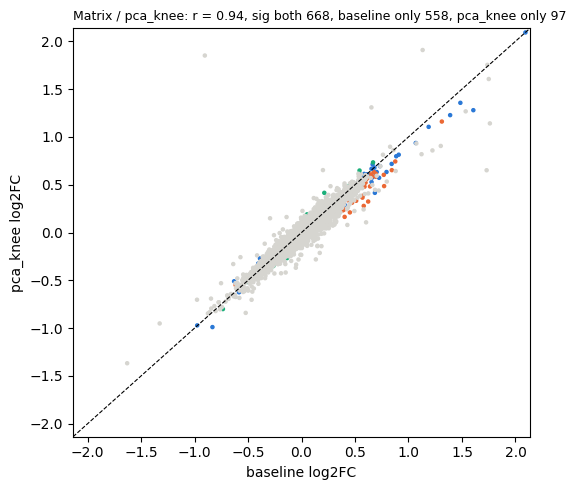

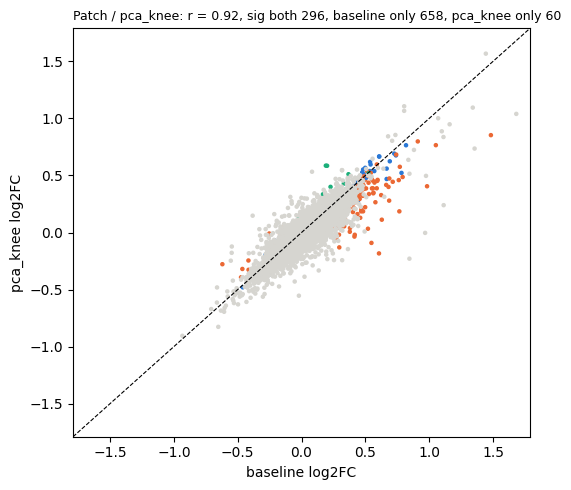

In [ ]:
for group in results:
    other = [name for name in results[group] if name != "baseline"]
    if not other:
        continue
    fig, axes = plt.subplots(1, len(other), figsize=(5.5 * len(other), 5), squeeze=False)
    for ax, name in zip(axes[0], other):
        both = results[group]["baseline"].merge(results[group][name], on="gene_id", suffixes=("_base", "_model"))
        both = both[both["converged_base"] & both["converged_model"]]
        sig_base, sig_model = both[f"{P_ADJ}_base"] < FDR, both[f"{P_ADJ}_model"] < FDR
        color = np.select([sig_base & sig_model, sig_base, sig_model], ["#2a78d6", "#eb6834", "#1baf7a"], "#d6d5d0")

        ax.scatter(both[f"{LFC}_base"], both[f"{LFC}_model"], s=5, c=color)
        lim = both[[f"{LFC}_base", f"{LFC}_model"]].abs().quantile(0.999).max()
        ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
        ax.set_xlabel("baseline log2FC")
        ax.set_ylabel(f"{name} log2FC")
        r = both[[f"{LFC}_base", f"{LFC}_model"]].corr().iloc[0, 1]
        ax.set_title(f"{group} / {name}: r = {r:.2f}, sig both {(sig_base & sig_model).sum()}, "
                     f"baseline only {(sig_base & ~sig_model).sum()}, {name} only {(~sig_base & sig_model).sum()}", fontsize=9, loc="left")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{group}_models_vs_baseline.png", dpi=150)
    plt.show()

### Volcano plots
Dark = FDR < `FDR`, coloured = Handsaker phase genes. Labels: the `N_LABELS` significant genes with the largest |log2FC|.

2026-11-04 22:43:48 | [INFO] cffi mode is CFFI_MODE.ANY
2026-11-04 22:43:48 | [INFO] R home found: /usr/lib/R
2026-11-04 22:43:48 | [INFO] R library path: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64
2026-11-04 22:43:48 | [INFO] LD_LIBRARY_PATH: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64


2026-11-04 22:43:48 | [INFO] Default options to initialize R: rpy2, --quiet, --no-save
2026-11-04 22:43:48 | [INFO] Environment variable "LD_LIBRARY_PATH" redefined by R and overriding existing variable. Current: "/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64", R: "/usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64"
2026-11-04 22:43:48 | [INFO] Environment variable "PWD" redefined by R and overriding existing variable. Current: "/home/gdallagl", R: "/home/gdallagl/myworkdir/XDP/script/HD_Handsaker/DEG"
2026-11-04 22:43:48 | [INFO] R is already initialized. No need to initialize.
2026-11-04 22:43:51 | [WARNING] Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.
/home/gdallagl/myworkdir/

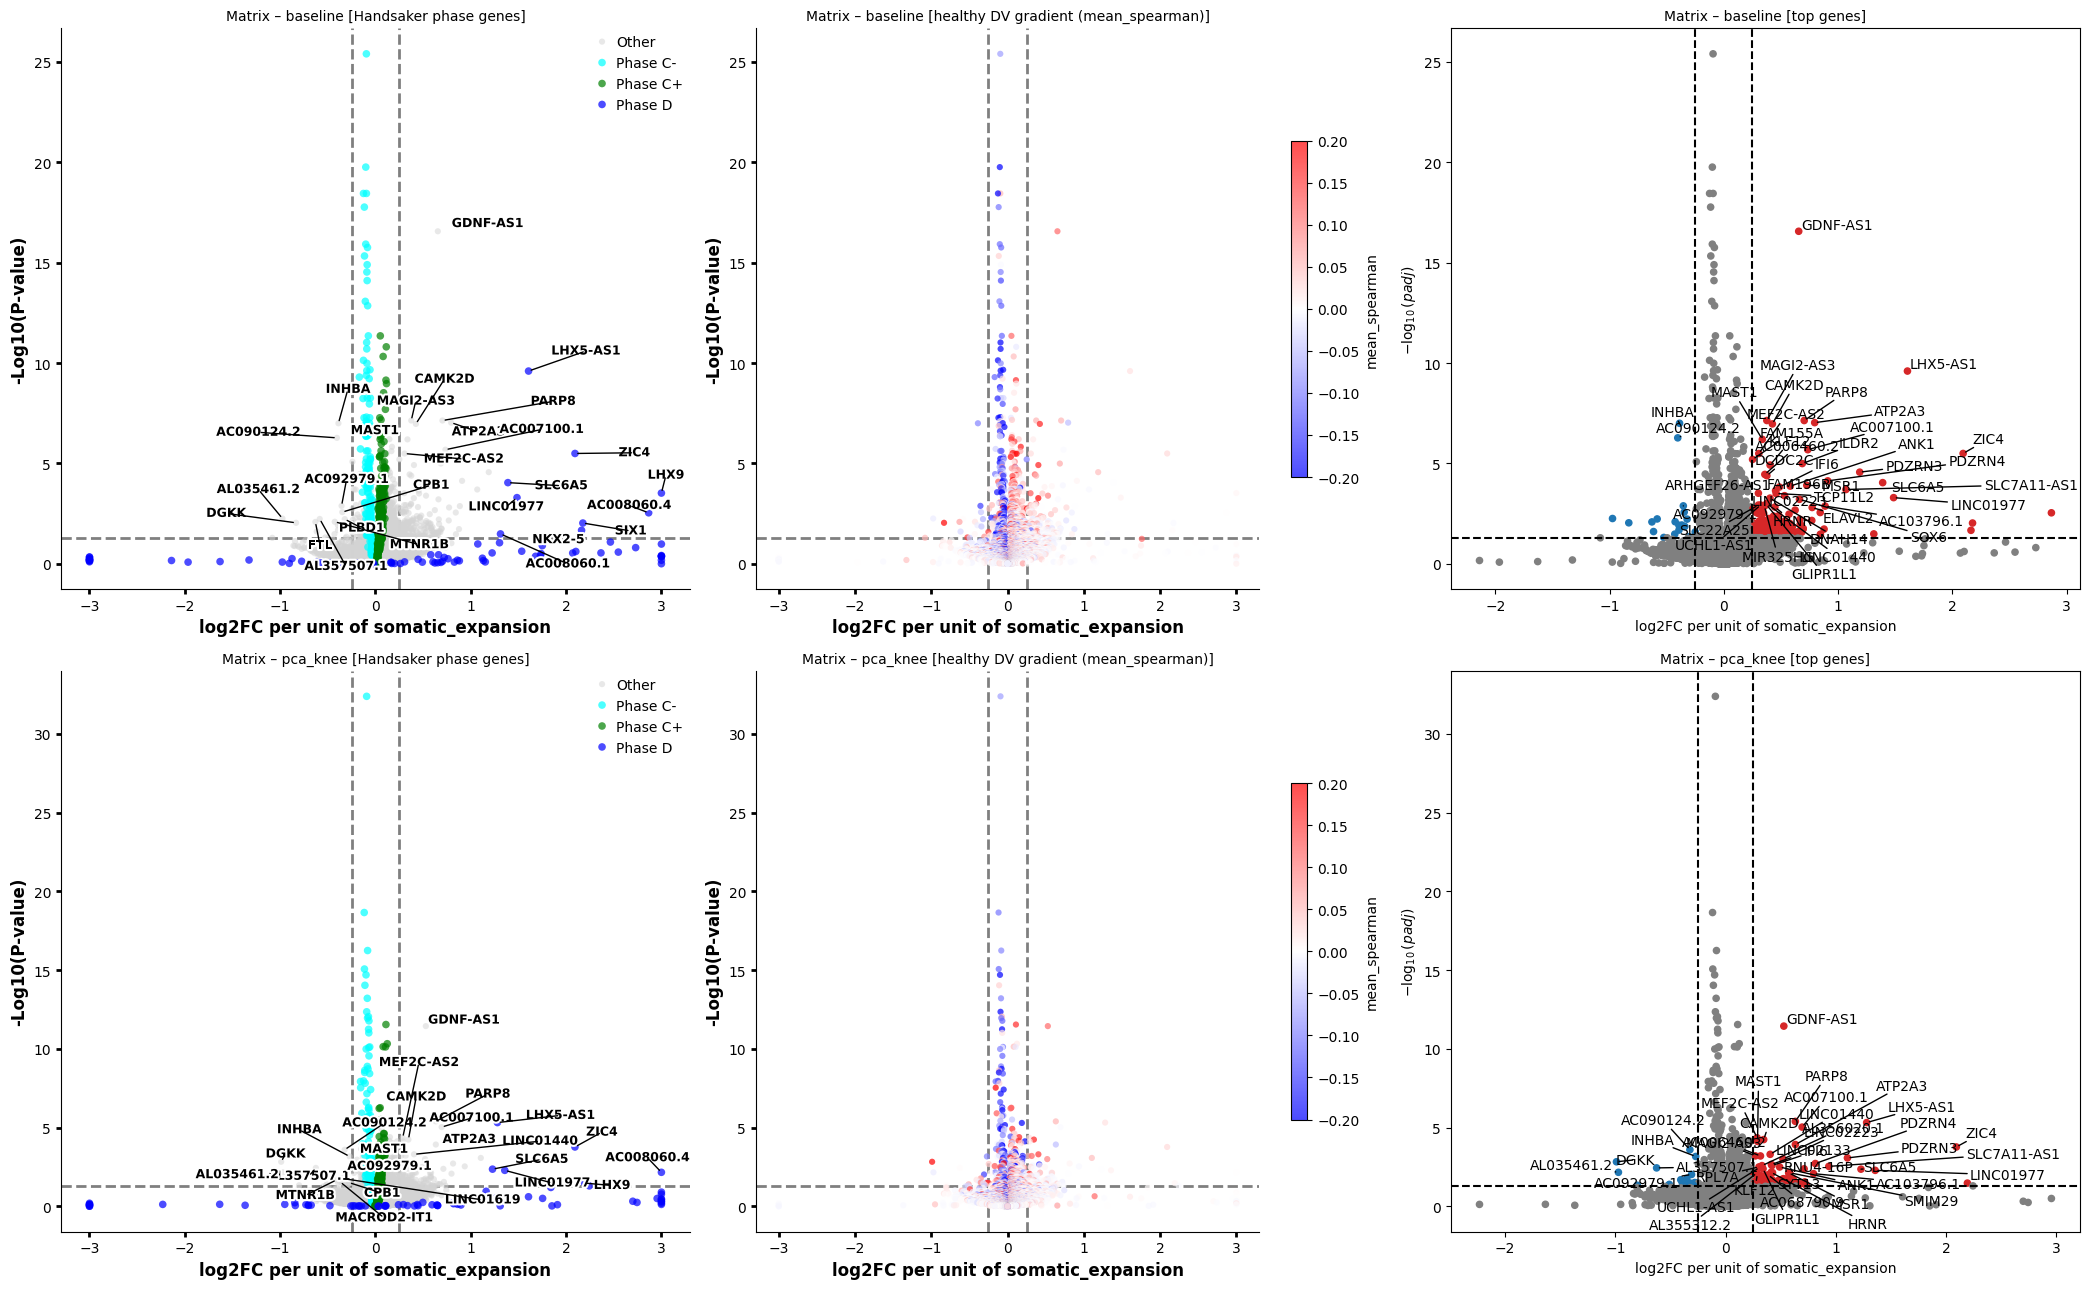

/home/gdallagl/myworkdir/XDP/utils/DEG.py:955: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)
/home/gdallagl/myworkdir/XDP/utils/DEG.py:955: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)


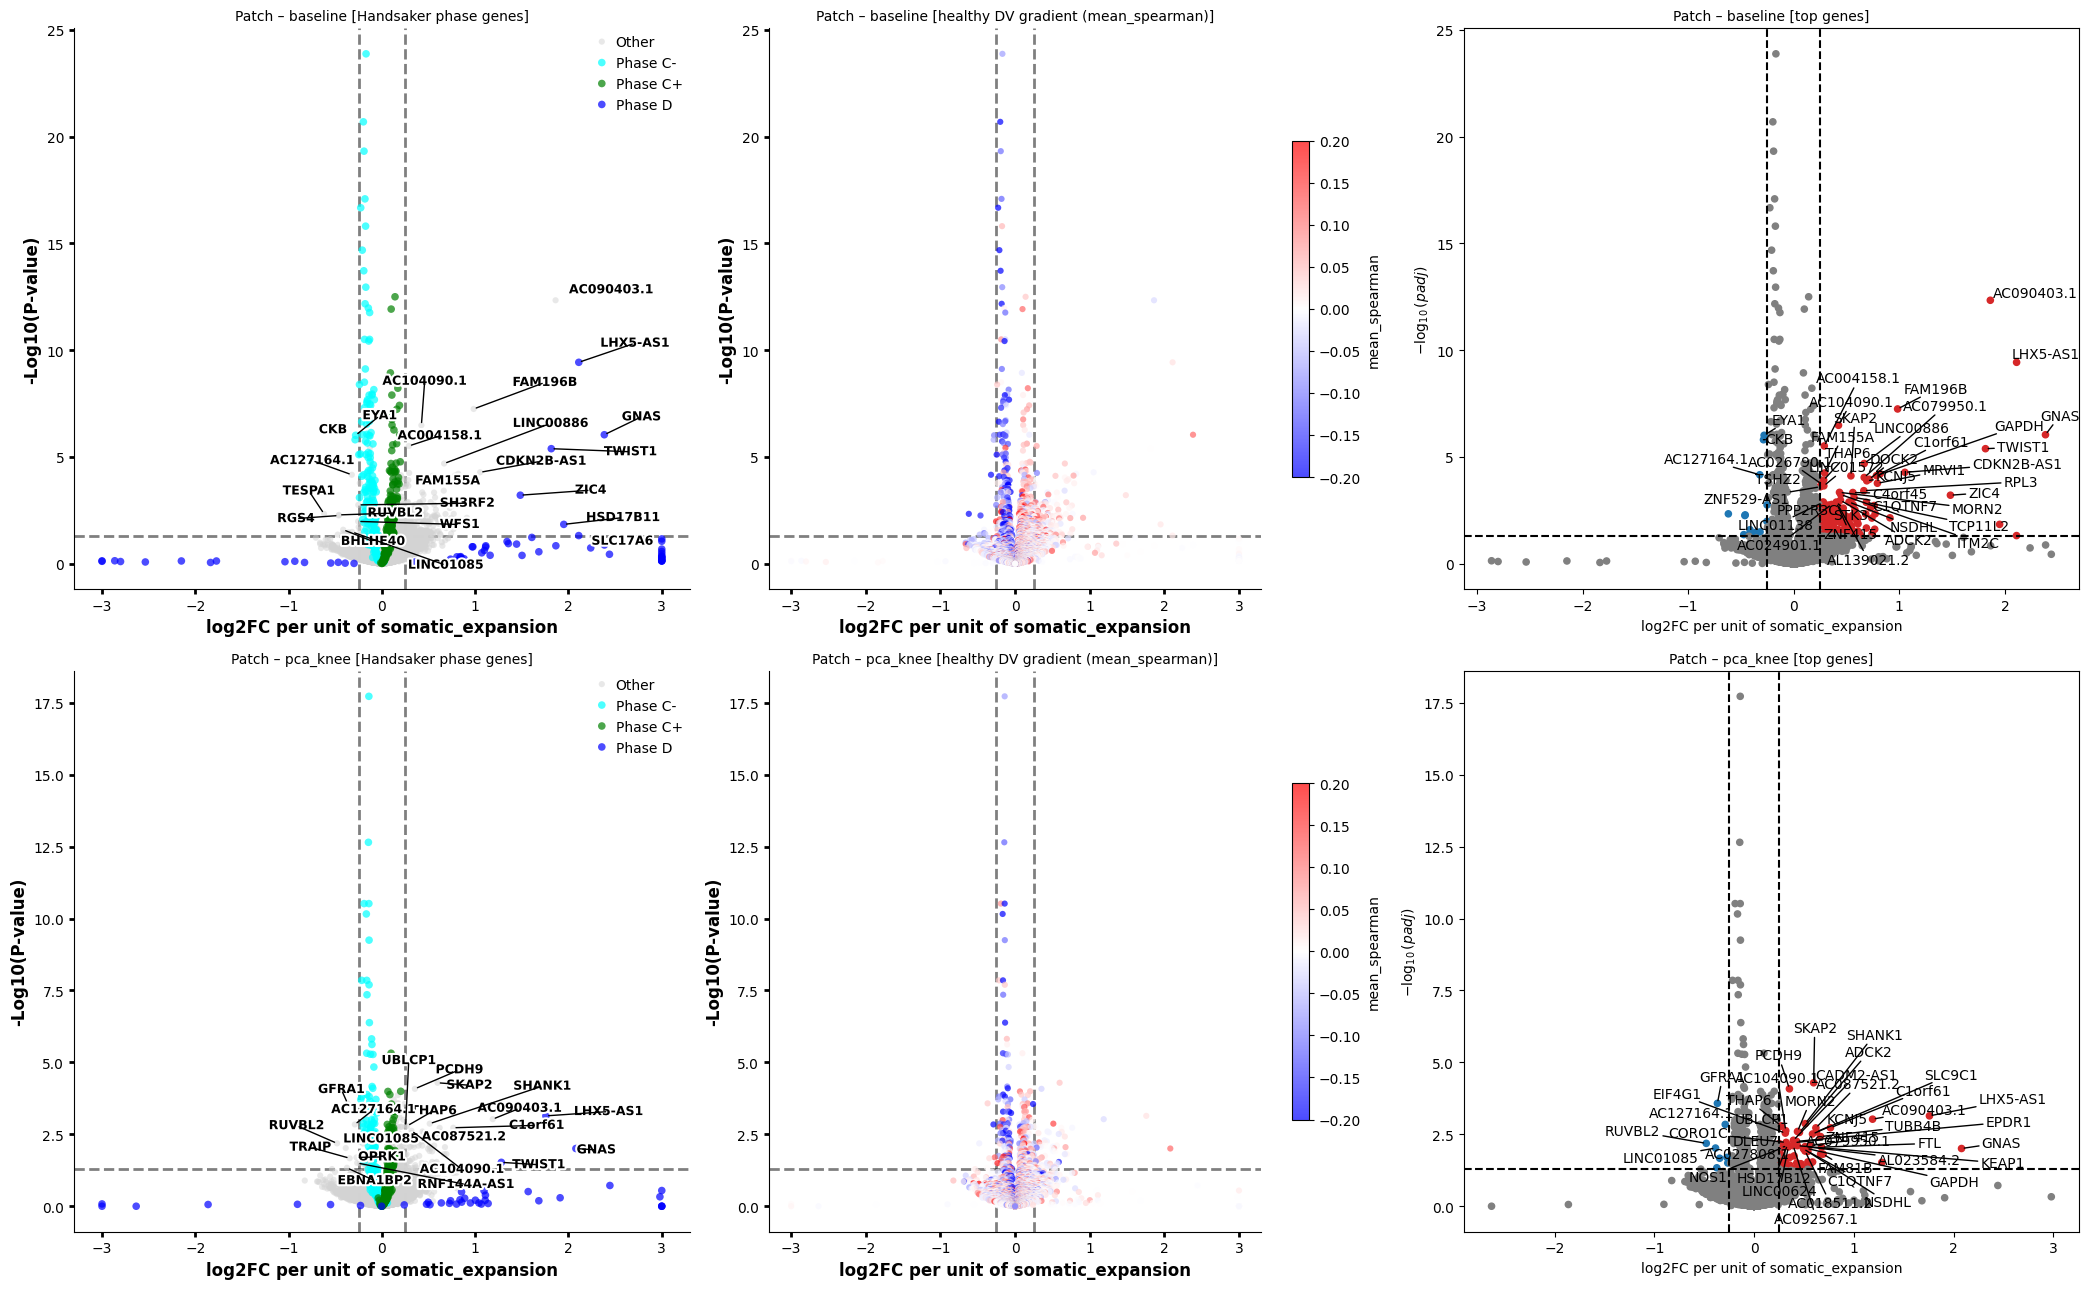

In [ ]:
import decoupler as dc
from utils import DEG
%matplotlib inline

LOGFC_THR = 0.25     # volcano: vertical lines (log2FC per unit of the response)

# Handsaker phase genes and healthy dorsal-ventral gradient (same files as Handsaker_DEG_on _repeats.ipynb)
categories_handsaker_phases = {
    "Phase D":  (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_d_genes.csv")["Gene"].tolist(), "blue"),
    "Phase C+": (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_c_plus_genes.csv")["Gene"].tolist(), "green"),
    "Phase C-": (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_c_minus_genes.csv")["Gene"].tolist(), "cyan"),
}
df_grad = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/dorsal_ventral_gradient/exp_by_spline_combined.csv").set_index("gene")
x_label = f"log2FC per unit of {RESPONSE}" if RESPONSE_TYPE == "numeric" else f"log2FC {RESPONSE_TESTED} vs {RESPONSE_BASELINE}"

for group in results:
    fig, axes = plt.subplots(len(results[group]), 3, figsize=(21, 6.5 * len(results[group])), squeeze=False)

    for row, (name, r) in zip(axes, results[group].items()):
        # converged genes, with the healthy gradient of each gene
        df = r[r["converged"]].merge(df_grad[["mean_spearman"]], how="left", left_on="gene_name", right_index=True)
        ax1, ax2, ax3 = row

        MAX_X = 3     # volcano x-axis: |log2FC| above this is drawn at the edge
        df = df.assign(**{LFC: df[LFC].clip(-MAX_X, MAX_X)})

        # Handsaker phase genes
        DEG.plot_vulcano(df, logfc_col=LFC, pval_col=P_ADJ, gene_col="gene_name",
                         pval_thresh=FDR, logfc_thresh=LOGFC_THR, to_label=N_LABELS,
                         categories=categories_handsaker_phases, max_y=None, ax=ax1, print_labels=True)
        # healthy dorsal-ventral gradient of each gene (red/blue = up/down along the gradient)
        DEG.plot_vulcano(df, logfc_col=LFC, pval_col=P_ADJ, gene_col="gene_name",
                         pval_thresh=FDR, logfc_thresh=LOGFC_THR, to_label=0,
                         color_by="mean_spearman", cmap="bwr", vmin=-0.2, vmax=0.2,
                         max_y=None, ax=ax2, print_labels=False)
        # top genes labelled (gene names can repeat across Ensembl IDs: keep the most significant)
        top = df.sort_values(P_ADJ).drop_duplicates("gene_name").set_index("gene_name")
        dc.pl.volcano(top.rename(columns={P_ADJ: "padj", LFC: "logFC"}),
                      x="logFC", y="padj", top=40, thr_stat=LOGFC_THR, thr_sign=FDR, max_stat=3, ax=ax3)

        for ax, lbl in zip(row, ["Handsaker phase genes", "healthy DV gradient (mean_spearman)", "top genes"]):
            ax.set_title(f"{group} – {name} [{lbl}]", fontsize=10)
            ax.set_xlabel(x_label)

    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{group}_volcano_all_models.png", dpi=150, bbox_inches="tight")
    plt.show()


In [ ]:
# For each gene, the baseline effect splits into the effect at a fixed factor value plus a part through the factors:
#     log2FC_baseline  ≈  log2FC_model  +  sum_k log2FC_factor_k(gene) * delta_k
# delta_k = shift of factor k (as in the NEBULA design) per unit of the response, from the LMM
#           factor_k ~ response + covariates + (1|donor) on the design table of the group
#   log2FC_model                     = response effect at fixed position on the factors
#   sum_k log2FC_factor_k * delta_k  = positional component: confounding OR a response effect that moves cells along the
#                                      factors (the data cannot separate the two)
phase_of_gene = {g: label for phase, label in [("c_plus", "C+"), ("c_minus", "C-"), ("d", "D")]
                 for g in pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"]}
df_grad = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/dorsal_ventral_gradient/exp_by_spline_combined.csv").set_index("gene")
response_param = RESPONSE if RESPONSE_TYPE == "numeric" else f"{RESPONSE}[T.{RESPONSE_TESTED}]"

decomp = {}
for group in results:
    design = pd.read_csv(f"{OUT_DIR}/{group}/design_table.csv", index_col=0)
    rhs = " + ".join([RESPONSE, *covariates[group]])
    base = results[group]["baseline"].set_index("gene_id")

    for name, factors in models[group].items():
        if name == "baseline" or not factors:
            continue
        model = results[group][name].set_index("gene_id")

        # delta_k of each factor
        delta = {}
        for f in factors:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = smf.mixedlm(f"{f} ~ {rhs}", design, groups=design[DONOR_COL]).fit(reml=True)
            delta[f] = {"delta": fit.params[response_param], "p": fit.pvalues[response_param]}

        # genes converged in both models
        g = base.index[base["converged"]].intersection(model.index[model["converged"]])
        d = pd.DataFrame({
            "gene_name": model.loc[g, "gene_name"],
            "logFC_baseline": base.loc[g, LFC],
            "logFC_adjusted": model.loc[g, LFC],
            "positional_component": sum(model.loc[g, f"log2FC_{f}"] * delta[f]["delta"] for f in factors),
            "sig_baseline": base.loc[g, P_ADJ] < FDR,
            "sig_adjusted": model.loc[g, P_ADJ] < FDR,
            "n_cells_detected": model.loc[g, "n_cells_detected"],
        })
        d["mean_spearman"] = d["gene_name"].map(df_grad["mean_spearman"])
        d["phase"] = d["gene_name"].map(phase_of_gene).fillna("")
        only = f"revealed by adjustment ({name} only)"
        d["category"] = np.select(
            [d.sig_baseline & d.sig_adjusted & (np.sign(d.logFC_baseline) == np.sign(d.logFC_adjusted)),
             d.sig_baseline & ~d.sig_adjusted,
             ~d.sig_baseline & d.sig_adjusted],
            ["robust (both)", "position-dependent (baseline only)", only],
            "not significant")
        decomp[(group, name)] = d
        d.to_csv(f"{OUT_DIR}/{group}/{name}/response_effect_position_decomposition.csv")

        check = np.corrcoef(d.logFC_baseline - d.logFC_adjusted, d.positional_component)[0, 1]
        print(f"\n######## {group} / {name}: {len(factors)} factors; corr(baseline - adjusted, positional component) = {check:.2f}")
        display(pd.DataFrame(delta).T.rename(columns={"delta": f"delta (factor units per unit of {RESPONSE})"}).round(4))
        display(pd.crosstab(d["category"], d["phase"].replace("", "other"), margins=True))



######## Matrix / pca_knee: 6 factors; corr(baseline - adjusted, positional component) = 0.07


,delta (factor units per unit of somatic_expansion),p
PC_1,-0.0739,0.0002
PC_2,-0.0551,0.0000
PC_3,0.0375,0.0093
PC_4,0.0042,0.6279
PC_5,-0.0183,0.3122
PC_6,-0.1165,0.0000


phase,C+,C-,D,other,All
category,,,,,
not significant,79,31,67,20072,20249
position-dependent (baseline only),52,31,3,472,558
revealed by adjustment (pca_knee only),3,1,0,93,97
robust (both),117,108,6,437,668
All,251,171,76,21074,21572



######## Patch / pca_knee: 9 factors; corr(baseline - adjusted, positional component) = 0.67


,delta (factor units per unit of somatic_expansion),p
PC_1,-0.1708,0.0000
PC_2,-0.1275,0.0000
PC_3,-0.0565,0.0007
PC_4,0.1049,0.0000
PC_5,-0.0747,0.0181
PC_6,0.2061,0.0000
PC_7,-0.1057,0.0017
PC_8,0.2489,0.0000
PC_9,0.1442,0.0000


phase,C+,C-,D,other,All
category,,,,,
not significant,110,45,34,14411,14600
position-dependent (baseline only),86,53,3,516,658
revealed by adjustment (pca_knee only),2,4,0,54,60
robust (both),59,78,3,156,296
All,257,180,40,15137,15614


In [ ]:
for (group, name), d in decomp.items():
    print(f"\n######## {group} / {name}")
    for cat in ["robust (both)", "position-dependent (baseline only)", f"revealed by adjustment ({name} only)"]:
        top = d[d["category"] == cat]
        top = top.reindex(top["logFC_baseline"].abs().sort_values(ascending=False).index)
        print(f"{cat}: {len(top)} genes")
        display(top.head(30)[["gene_name", "logFC_baseline", "logFC_adjusted", "positional_component",
                              "mean_spearman", "phase", "n_cells_detected"]].round(3))



######## Matrix / pca_knee
robust (both): 668 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000143355,LHX9,3.003,2.193,0.277,0.008,D,7
ENSG00000260426,AC008060.4,2.866,3.530,-0.049,0.000,D,5
ENSG00000174963,ZIC4,2.093,2.093,0.019,0.029,D,15
ENSG00000257935,LHX5-AS1,1.606,1.280,0.198,0.023,D,49
ENSG00000262772,LINC01977,1.485,1.357,0.152,0.010,D,25
ENSG00000165970,SLC6A5,1.389,1.228,0.047,-0.000,D,33
ENSG00000121440,PDZRN3,1.189,1.105,0.097,0.050,,126
ENSG00000250033,SLC7A11-AS1,1.068,0.937,0.086,-0.005,,128
ENSG00000275632,AL035461.2,-0.975,-0.972,0.076,-0.014,,166


position-dependent (baseline only): 558 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000126778,SIX1,2.176,2.244,0.047,-0.004,D,6
ENSG00000183072,NKX2-5,2.162,1.840,0.060,0.002,D,7
ENSG00000218672,AC008060.1,1.312,1.161,0.073,-0.002,D,13
ENSG00000249815,AC004704.1,0.876,0.743,0.070,-0.022,,151
ENSG00000229395,AC062039.1,0.844,0.653,0.102,0.011,,94
ENSG00000107105,ELAVL2,0.772,0.486,0.207,0.030,,182
ENSG00000228512,AL160272.1,0.769,0.603,0.074,-0.023,,161
ENSG00000232243,AL139327.2,0.694,0.616,0.060,-0.016,,88
ENSG00000221887,HMSD,0.693,0.584,0.081,-0.005,,97


revealed by adjustment (pca_knee only): 97 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000226699,AL360181.1,-0.735,-0.801,0.089,0.003,,137
ENSG00000230392,AC004835.1,0.669,0.734,-0.069,-0.004,,82
ENSG00000172403,SYNPO2,0.542,0.649,-0.038,0.037,,162
ENSG00000255306,AC004923.4,-0.496,-0.519,0.029,-0.036,,292
ENSG00000160867,FGFR4,0.450,0.496,-0.030,-0.014,,171
ENSG00000228484,AL137025.1,0.417,0.465,0.017,0.004,,246
ENSG00000235236,AC137630.2,0.395,0.427,-0.004,-0.001,,250
ENSG00000224919,AL591684.1,0.323,0.339,0.015,-0.002,,397
ENSG00000225057,AC012485.1,0.307,0.370,-0.031,-0.008,,385


... (2 outputs left out)

position-dependent (baseline only): 658 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000091664,SLC17A6,2.110,3.613,0.011,0.017,D,4
ENSG00000198189,HSD17B11,1.950,1.110,0.639,0.019,D,6
ENSG00000174963,ZIC4,1.484,0.854,0.590,0.029,D,16
ENSG00000240498,CDKN2B-AS1,1.052,0.766,0.173,-0.009,,80
ENSG00000204767,FAM196B,0.983,0.406,0.605,NaN,,145
ENSG00000213121,AL590867.1,0.911,0.799,0.135,0.071,,87
ENSG00000072952,MRVI1,0.792,0.487,0.291,0.012,,98
ENSG00000172497,ACOT12,0.770,0.576,0.189,-0.005,,92
ENSG00000072657,TRHDE,0.766,0.186,0.389,0.025,,81


revealed by adjustment (pca_knee only): 60 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000161970,RPL26,0.524,0.519,0.102,-0.032,,110
ENSG00000237851,AL023584.2,0.368,0.511,-0.179,-0.008,,145
ENSG00000196943,NOP9,0.331,0.429,-0.100,-0.015,,160
ENSG00000232940,HCG25,0.293,0.364,-0.109,0.005,,242
ENSG00000255545,AP004608.1,0.262,0.357,-0.060,0.069,,342
ENSG00000183763,TRAIP,-0.239,-0.346,0.111,0.025,,410
ENSG00000101134,DOK5,0.227,0.400,-0.102,0.009,,306
ENSG00000182177,ASB18,0.222,0.277,-0.032,-0.102,,582
ENSG00000259546,AC027808.1,0.213,0.307,-0.028,NaN,,482
